# Experiment Analysis Notebook

This notebook is for analyzing the results of the AI Perfectionism and Semantic Drift experiments. It loads the most recent experiment data from the `results` directory, displays a summary of the experiment, and provides an initial analysis of the metrics.

--- Experiment Summary ---
Prompt: What are the implications of AI in modern society?
Model A: gpt-4
Model B: gpt-3.5-turbo
Iterations: 10
--- Results Plot ---


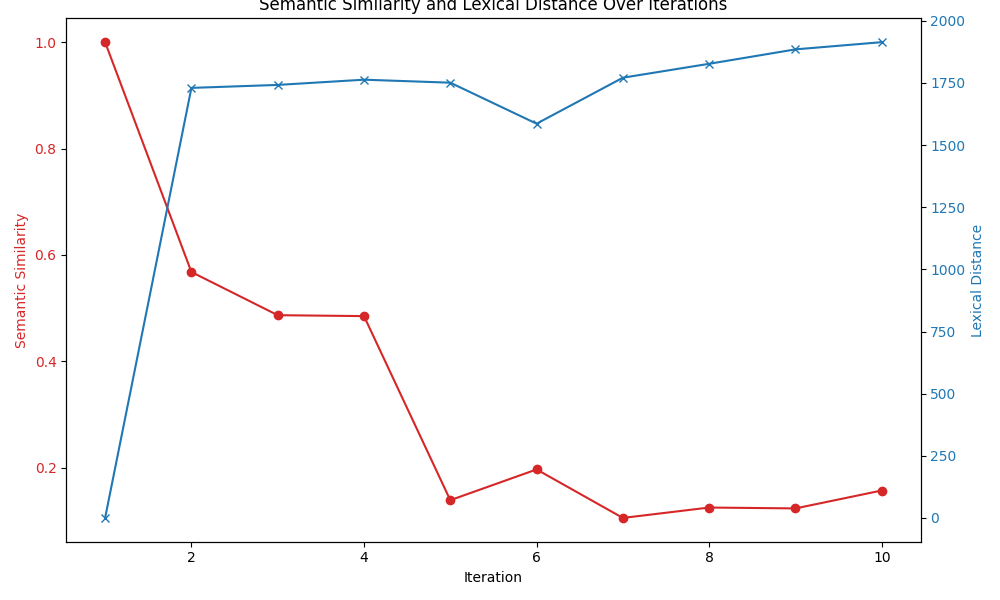

--- Metrics Over Time ---


,iteration,semantic_similarity,lexical_distance
0,1,1.000000,0
1,2,0.567957,1730
2,3,0.486803,1742
3,4,0.485055,1763
4,5,0.139052,1751
5,6,0.196854,1586
6,7,0.105699,1771
7,8,0.125233,1827
8,9,0.123595,1885
9,10,0.157261,1914


--- Initial Analysis ---
Final Semantic Similarity: 0.16
Final Lexical Distance: 1914
Conclusion: There appears to be a significant semantic drift.


In [1]:
import os
import json
import pandas as pd
from IPython.display import Image, display

# Find the most recent results file
results_dir = '../results'
latest_file = sorted([f for f in os.listdir(results_dir) if f.endswith('.json')])[-1]
results_path = os.path.join(results_dir, latest_file)
plot_path = results_path.replace('.json', '.png')

# Load the results data
with open(results_path, 'r') as f:
    data = json.load(f)

# Display experiment summary
print(f"--- Experiment Summary ---")
print(f"Prompt: {data['prompt']}")
print(f"Model A: {data['model_a']}")
print(f"Model B: {data['model_b']}")
print(f"Iterations: {data['iterations']}")

# Display the plot
print("--- Results Plot ---")
if os.path.exists(plot_path):
    display(Image(filename=plot_path))
else:
    print("Plot not found.")

# Create and display a DataFrame of the metrics
print("--- Metrics Over Time ---")
metrics_df = pd.DataFrame(data['metrics']['metrics_over_time'])
display(metrics_df)

# Initial Analysis
print("--- Initial Analysis ---")
final_similarity = metrics_df['semantic_similarity'].iloc[-1]
final_distance = metrics_df['lexical_distance'].iloc[-1]

print(f"Final Semantic Similarity: {final_similarity:.2f}")
print(f"Final Lexical Distance: {final_distance}")

if final_similarity < 0.5:
    print("Conclusion: There appears to be a significant semantic drift.")
else:
    print("Conclusion: The semantic drift appears to be less significant.")